In [2]:
%pip install scikit-learn

     ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
     ---------------------------------------- 0.0/8.9 MB 1.4 MB/s eta 0:00:07
     ---------------------------------------- 0.1/8.9 MB 1.2 MB/s eta 0:00:08
     - -------------------------------------- 0.2/8.9 MB 1.7 MB/s eta 0:00:06
     - -------------------------------------- 0.3/8.9 MB 2.1 MB/s eta 0:00:05
     -- ------------------------------------- 0.5/8.9 MB 2.5 MB/s eta 0:00:04
     --- ------------------------------------ 0.7/8.9 MB 2.8 MB/s eta 0:00:03
     ----- ---------------------------------- 1.2/8.9 MB 4.1 MB/s eta 0:00:02
     ------ --------------------------------- 1.5/8.9 MB 4.3 MB/s eta 0:00:02
     -------- ------------------------------- 1.9/8.9 MB 5.1 MB/s eta 0:00:02
     ---------- ----------------------------- 2.3/8.9 MB 5.7 MB/s eta 0:00:02
     ------------ --------------------------- 2.8/8.9 MB 6.1 MB/s eta 0:00:01
     -------------- ------------------------- 3.1/8.9 MB 6.4 MB/s eta 0


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: C:\Users\ACER\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 1. Loading the Dataset

The Iris dataset is built into scikit-learn, so no download was needed. I loaded it
as a pandas DataFrame and added a `species` column that converts the numeric target
(0, 1, 2) into readable names: setosa, versicolor, and virginica. The dataset has
four numeric features (sepal length, sepal width, petal length, petal width) that
describe each flower.

In [4]:
%pip install numpy matplotlib seaborn nltk wordcloud

  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
     ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
      --------------------------------------- 0.0/1.8 MB 1.4 MB/s eta 0:00:02
     -- ------------------------------------- 0.1/1.8 MB 1.3 MB/s eta 0:00:02
     ----- ---------------------------------- 0.2/1.8 MB 1.7 MB/s eta 0:00:01
     -------- ------------------------------- 0.4/1.8 MB 2.5 MB/s eta 0:00:01
     ------------- -------------------------- 0.6/1.8 MB 2.9 MB/s eta 0:00:01
     ------------------- -------------------- 0.9/1.8 MB 3.4 MB/s eta 0:00:01
     ------------------------ --------------- 1.1/1.8 MB 3.7 MB/s eta 0:00:01
     ------------------------------ --------- 1.4/1.8 MB 4.1 MB/s eta 0:00:01
     ------------------------------------ --- 1.6/1.8 MB 4.3 MB/s eta 0:00:01
     ---------------------------------------  1.8/1.8 MB 4.4 MB/s eta 0:00:01
     ---------------------------------------- 1.8/1.8 MB 4.2 MB/s eta 0:00:00
     ----------


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: C:\Users\ACER\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [5]:
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df.shape

(150, 6)

Now EDA is performed in the data

In [11]:
df.dtypes

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species               object
dtype: object

In [12]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [14]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

In [15]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [16]:
df['species'].value_counts(normalize=True)

species
setosa        0.333333
versicolor    0.333333
virginica     0.333333
Name: proportion, dtype: float64

Now Visualizing for patterns

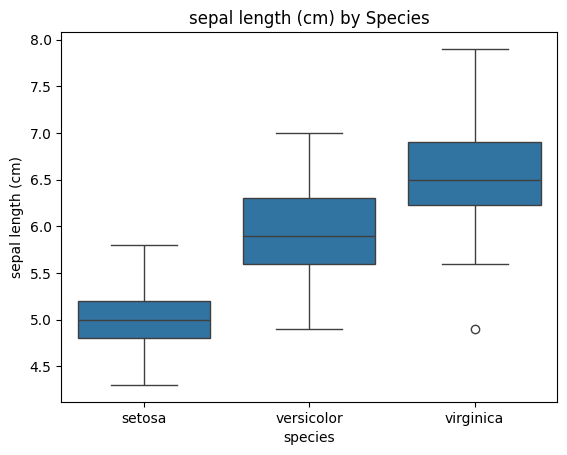

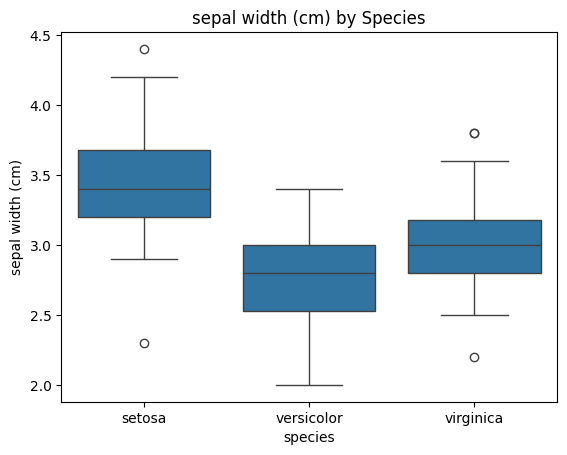

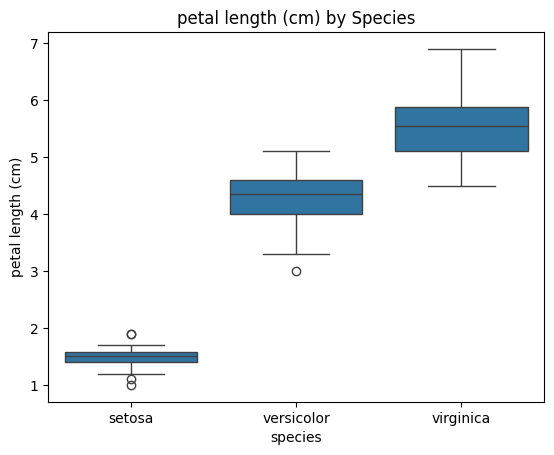

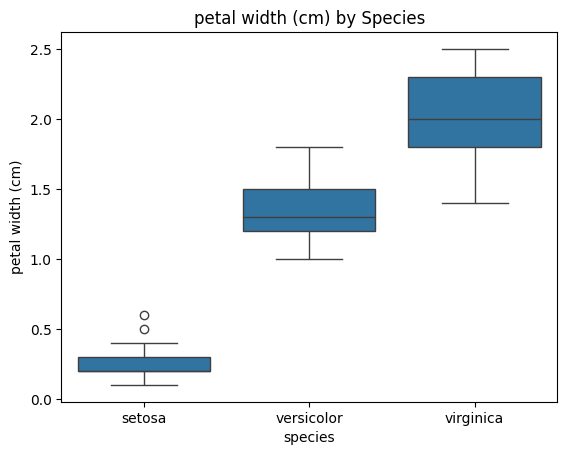

In [20]:
features = ['sepal length (cm)', 'sepal width (cm)',
            'petal length (cm)', 'petal width (cm)']

for col in features:
    sns.boxplot(data=df, x='species', y=col)
    plt.title(f'{col} by Species')
    plt.show()

 Feature Discussion

Petal length and petal width are the most discriminative features. Setosa is
completely separated by both, and versicolor and virginica overlap only slightly.
Sepal length gives moderate separation, while sepal width has heavy overlap
between all species and is the least useful. A classifier should therefore rely
mostly on the petal measurements.

In [23]:
X = iris.data
y = iris.target

In [24]:
print(type(iris))
print(iris.feature_names)
print(iris.target_names)

<class 'sklearn.utils._bunch.Bunch'>
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [26]:
print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(120, 4) (30, 4)
target
0    40
2    40
1    40
Name: count, dtype: int64
target
0    10
2    10
1    10
Name: count, dtype: int64


Now, Training the two models


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [28]:
lr = LogisticRegression(max_iter=200)
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [29]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


 Model Training

I trained two classifiers on the training set: Logistic Regression, a simple linear
model, and Random Forest, an ensemble of decision trees. Using two different types
of model lets me compare a simple approach against a more flexible one.

In [30]:
pred_lr = lr.predict(X_test)
print(pred_lr)

[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


In [33]:
print(y_test.values)

[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [34]:
from sklearn.metrics import accuracy_score

print(accuracy_score(y_test, pred_lr))

0.9666666666666667


In [35]:
pred_rf = rf.predict(X_test)
print(accuracy_score(y_test, pred_rf))

0.9


In [36]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test, pred_lr))
print(classification_report(y_test, pred_lr, target_names=iris.target_names))

[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



 Evaluation: Logistic Regression

The model reached an accuracy of 0.97 on the test set (29 of 30 correct). Setosa
was classified perfectly. One versicolor flower was misclassified as virginica,
which lowered versicolor recall to 0.90 and virginica precision to 0.91. This
agrees with the box plots, where versicolor and virginica overlapped slightly.

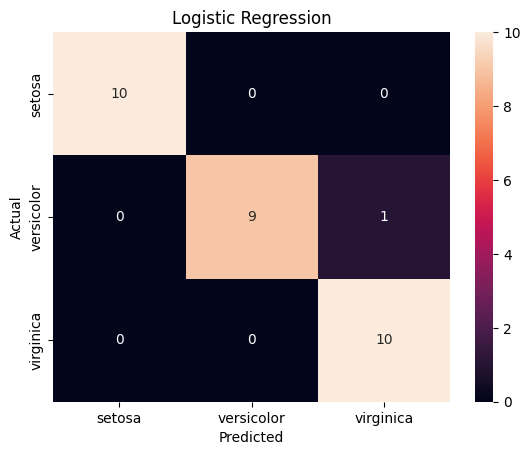

In [37]:
sns.heatmap(confusion_matrix(y_test, pred_lr), annot=True, fmt='d',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Logistic Regression')
plt.show()

The heatmap shows that Logistic Regression classified setosa and virginica
perfectly. The only error was one versicolor flower predicted as virginica. This
fits the box plots, where versicolor and virginica overlapped slightly.

0.9
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



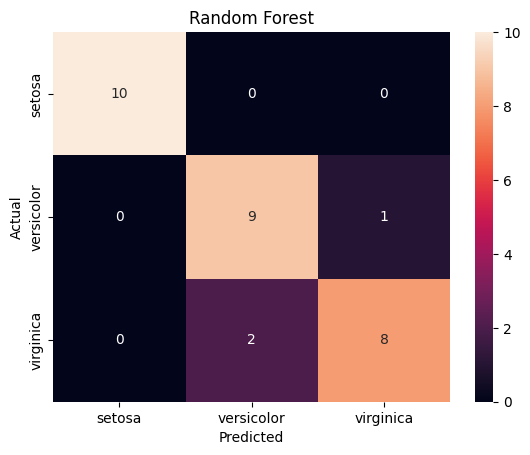

In [38]:
pred_rf = rf.predict(X_test)
print(accuracy_score(y_test, pred_rf))
print(classification_report(y_test, pred_rf, target_names=iris.target_names))

sns.heatmap(confusion_matrix(y_test, pred_rf), annot=True, fmt='d',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Random Forest')
plt.show()

In [40]:
from sklearn.model_selection import cross_val_score

print("LR:", cross_val_score(LogisticRegression(max_iter=200), X, y, cv=5).mean())
print("RF:", cross_val_score(RandomForestClassifier(random_state=42), X, y, cv=5).mean())

LR: 0.9733333333333334
RF: 0.9666666666666668


 Conclusion

Both models classified setosa perfectly, and all errors were between versicolor
and virginica, matching the overlap seen in the box plots.

On the single 80/20 test split, Logistic Regression scored 0.97 (1 error) and
Random Forest scored 0.90 (3 errors). However, with only 30 test samples, one
flower changes accuracy by 3.3%. 5-fold cross-validation gave a fairer comparison:
Logistic Regression 0.973 vs Random Forest 0.967, so the two models perform almost
equally well.

**Best model: Logistic Regression.** It scored highest in both evaluations, and
it is simpler, faster, and easier to interpret. The Iris classes are close to
linearly separable, which suits a linear model. The petal measurements were the
most discriminative features.

Random Forest feature importances confirmed that petal length and petal width matter most.

In [41]:
print(dict(zip(iris.feature_names, rf.feature_importances_.round(3))))

{'sepal length (cm)': np.float64(0.116), 'sepal width (cm)': np.float64(0.015), 'petal length (cm)': np.float64(0.431), 'petal width (cm)': np.float64(0.437)}
